# **Data Visualization — Global AI Jobs 2026**

**Nama:** Apriliana Trisnawati Dau  
**NIM:** 2418054  
**Mata Kuliah:** Data Mining  

## 1. Pendahuluan
Proyek ini bertujuan mengeksplorasi dataset Global AI Jobs 2026 melalui visualisasi data. Analisis berfokus pada distribusi spesialisasi AI, perbandingan gaji menurut tingkat pengalaman, negara dengan jumlah catatan pekerjaan terbanyak, dan ketersediaan kerja dari rumah.

> **Catatan interpretasi:** hasil hanya menggambarkan pola pada file yang dianalisis. Jangan menganggapnya otomatis mewakili seluruh pasar kerja AI dunia. Periksa dokumentasi dan sumber dataset sebelum membuat klaim faktual tentang pasar kerja.

## 2. Import library
Library yang digunakan: pandas untuk pengolahan data, matplotlib dan seaborn untuk visualisasi.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import files

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

## 3. Memuat dataset
Jalankan sel berikut, lalu unggah file `global_ai_jobs_2026.csv` dari komputer. Jika file sudah berada di folder kerja Colab, kode akan membacanya langsung.

In [ ]:
from google.colab import drive
from pathlib import Path

# Hubungkan Google Drive ke Google Colab
drive.mount('/content/drive')

# Lokasi dataset di Google Drive
file_path = '/content/drive/MyDrive/Colab Notebooks/dataset/global_ai_jobs_2026.csv'

# Baca dataset
df = pd.read_csv(file_path)

# Tampilkan informasi dataset
print(f"Jumlah baris: {df.shape[0]:,}")
print(f"Jumlah kolom: {df.shape[1]}")

# Tampilkan 5 baris pertama
display(df.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Jumlah baris: 5,000
Jumlah kolom: 37


,Job_ID,Job_Title,AI_Specialization,Industry,Company,Company_Size,Country,Continent,Education_Required,Experience_Level,...,Work_Life_Balance_1_10,AI_Investment_Company_Millions,Company_AI_Maturity_1_10,Job_Growth_Projection_%,Automation_Risk_%,Gender_Diversity_%_Female,Posted_Date,Application_Deadline,Record_Created,Data_Source
0,AI-03546,Business Intelligence Analyst,Computer Vision,E-commerce,Alibaba,Enterprise (5000+),Israel,Asia,Bachelor's,Executive,...,5.2,39,3.9,30.7,10.2,22.7,2035-09-16,2035-10-17,2026-08-28,Global AI Jobs Report 2026
1,AI-01969,Generative AI Engineer,Reinforcement Learning,Automotive,UiPath,Large (501-5000),United States,North America,Master's,Executive,...,7.3,499,3.9,18.1,20.7,39.8,2031-05-23,2031-06-23,2026-08-28,Global AI Jobs Report 2026
2,AI-02960,AI Software Engineer,Deep Learning,Insurance,UiPath,Enterprise (5000+),United States,North America,Postdoctoral,Executive,...,5.5,5,2.8,43.7,29.1,27.1,2034-02-07,2034-03-10,2026-08-28,Global AI Jobs Report 2026
3,AI-02384,NLP Engineer,Other,Transportation,Adobe,Large (501-5000),United States,North America,PhD,Executive,...,4.7,172,8.1,39.9,24.9,15.9,2032-07-11,2032-08-11,2026-08-28,Global AI Jobs Report 2026
4,AI-03930,AI Solutions Architect,Reinforcement Learning,Cloud Computing,Megvii,Large (501-5000),Switzerland,Europe,PhD,Executive,...,8.1,65,6.8,25.6,31.5,41.2,2036-10-04,2036-11-04,2026-08-28,Global AI Jobs Report 2026


## 4. Memahami struktur data
Periksa tipe data, ringkasan statistik, nilai kosong, dan duplikasi sebelum membuat grafik.

In [ ]:
print("Informasi dataset:")
df.info()

print("\\nJumlah nilai kosong per kolom (hanya kolom yang memiliki nilai kosong):")
missing = df.isna().sum()
display(missing[missing > 0].sort_values(ascending=False).to_frame("Jumlah_Nilai_Kosong"))

print(f"\\nJumlah baris duplikat: {df.duplicated().sum():,}")

print("\\nRingkasan statistik kolom numerik:")
display(df.describe().T)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 37 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Job_ID                          5000 non-null   object 
 1   Job_Title                       5000 non-null   object 
 2   AI_Specialization               5000 non-null   object 
 3   Industry                        5000 non-null   object 
 4   Company                         5000 non-null   object 
 5   Company_Size                    5000 non-null   object 
 6   Country                         5000 non-null   object 
 7   Continent                       5000 non-null   object 
 8   Education_Required              5000 non-null   object 
 9   Experience_Level                5000 non-null   object 
 10  Years_of_Experience             5000 non-null   int64  
 11  Salary_USD                      5000 non-null   float64
 12  Salary_Min     

,Jumlah_Nilai_Kosong
Required_Certifications,840


\nJumlah baris duplikat: 0
\nRingkasan statistik kolom numerik:


,count,mean,std,min,25%,50%,75%,max
Years_of_Experience,5000.0,7.57540,6.245263,0.0,2.00,7.00,12.000,20.0
Salary_USD,5000.0,158179.95840,78886.439234,27934.0,104261.25,141886.00,191695.000,718357.0
Salary_Min,5000.0,126656.83140,63920.017903,21398.0,83105.50,113983.00,154688.500,614788.0
Salary_Max,5000.0,197920.70540,100139.163004,34852.0,129468.00,176796.00,239955.750,917269.0
Bonus_%,5000.0,17.33884,7.238298,5.0,10.90,17.40,23.600,30.0
Benefits_Value_USD,5000.0,22363.49640,10110.624917,5002.0,13607.75,22412.00,31134.250,39989.0
Job_Openings,5000.0,10.07360,3.210209,1.0,8.00,10.00,12.000,22.0
Competition_Level_Applicants,5000.0,257.89520,141.564460,10.0,134.00,259.00,381.000,500.0
Hiring_Difficulty_1_10,5000.0,6.30412,1.884440,3.0,4.70,6.30,7.900,9.5
Remote_Work_%,5000.0,57.74800,26.115606,0.0,40.00,60.00,80.000,100.0


## 5. Pembersihan data
Buat salinan data, rapikan spasi pada kolom teks, ubah kolom tanggal menjadi format tanggal, dan pastikan kolom gaji berbentuk numerik. Nilai kosong pada sertifikasi tidak dihapus dari seluruh dataset karena informasi lain pada baris tersebut masih bisa digunakan.

In [ ]:
data = df.copy()

# Rapikan spasi pada kolom teks
text_cols = data.select_dtypes(include="object").columns
for col in text_cols:
    data[col] = data[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

# Konversi kolom tanggal bila tersedia
for col in ["Posted_Date", "Application_Deadline", "Record_Created"]:
    if col in data.columns:
        data[col] = pd.to_datetime(data[col], errors="coerce")

# Pastikan kolom gaji numerik
for col in ["Salary_USD", "Salary_Min", "Salary_Max"]:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Untuk analisis sertifikasi, nilai kosong dapat ditampilkan sebagai "Tidak dicantumkan"
if "Required_Certifications" in data.columns:
    data["Required_Certifications"] = data["Required_Certifications"].fillna("Tidak dicantumkan")

print("Ukuran data setelah pembersihan ringan:", data.shape)
print("Jumlah nilai kosong pada Salary_USD:", data["Salary_USD"].isna().sum() if "Salary_USD" in data.columns else "Kolom tidak ditemukan")

Ukuran data setelah pembersihan ringan: (5000, 37)
Jumlah nilai kosong pada Salary_USD: 0


## 6. Visualisasi 1 — Jumlah catatan berdasarkan spesialisasi AI
Grafik ini membandingkan jumlah baris untuk setiap kategori `AI_Specialization`. Jumlah baris bukan selalu sama dengan jumlah lowongan aktual; kolom `Job_Openings` dapat dianalisis terpisah jika ingin menghitung total posisi yang dibuka.

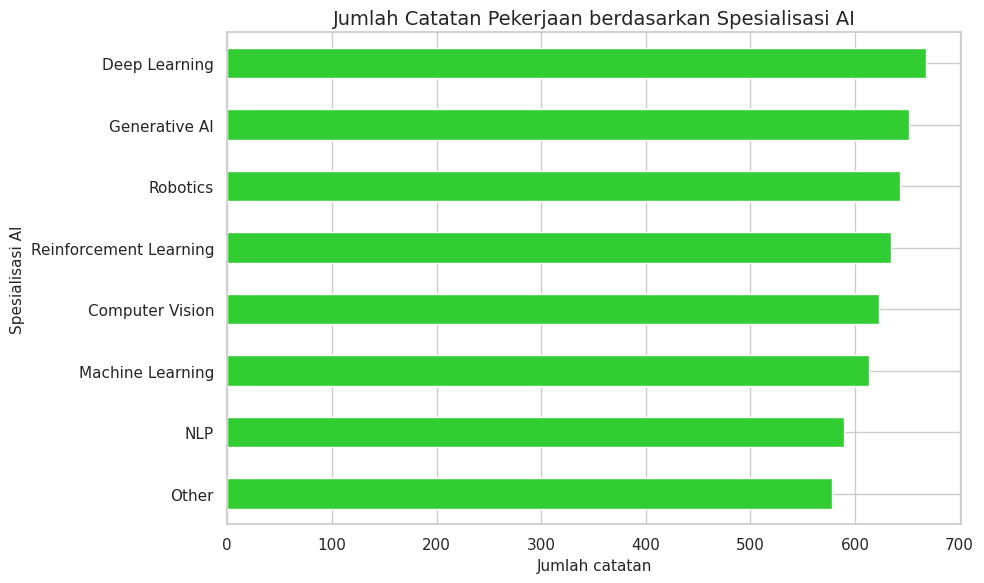

In [ ]:
if "AI_Specialization" in data.columns:
    specialization_counts = data["AI_Specialization"].value_counts().sort_values()
    ax = specialization_counts.plot(kind="barh", color="limegreen")
    ax.set_title("Jumlah Catatan Pekerjaan berdasarkan Spesialisasi AI")
    ax.set_xlabel("Jumlah catatan")
    ax.set_ylabel("Spesialisasi AI")
    plt.tight_layout()
    plt.show()
else:
    print("Kolom AI_Specialization tidak ditemukan.")

**Interpretasi:** kategori dengan batang terpanjang merupakan spesialisasi yang paling sering tercatat dalam file. Setelah grafik muncul, tulis nama kategori teratas dan jumlahnya berdasarkan hasil aktual.

## 7. Visualisasi 2 — Median gaji berdasarkan tingkat pengalaman
Median digunakan untuk mengurangi pengaruh nilai gaji ekstrem. Grafik hanya memasukkan baris yang memiliki nilai gaji numerik.

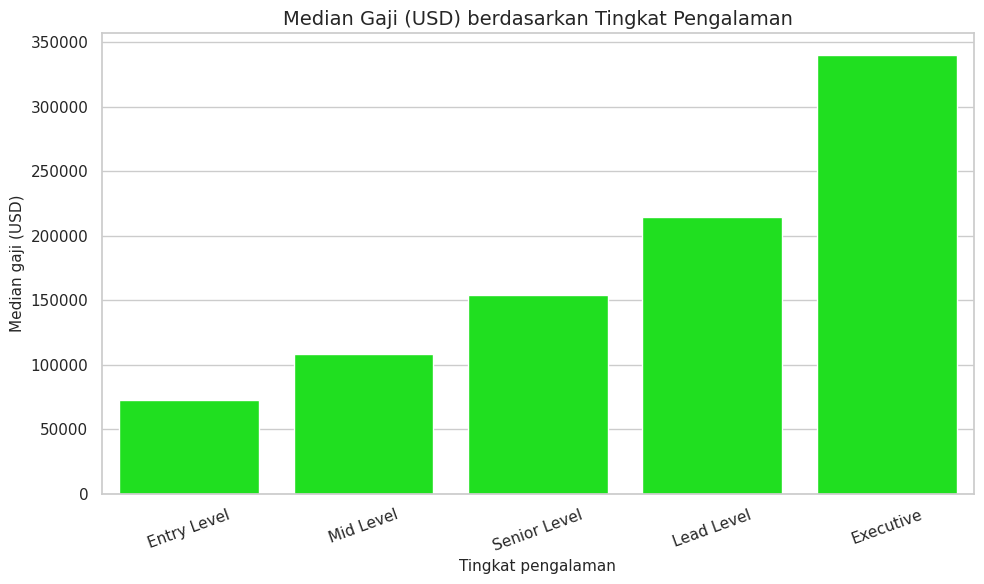

,Median_Gaji_USD
Experience_Level,
Executive,339774.0
Lead Level,214833.0
Senior Level,154104.5
Mid Level,108376.0
Entry Level,72536.0


In [ ]:
required = {"Experience_Level", "Salary_USD"}
if required.issubset(data.columns):
    salary_data = data.dropna(subset=["Experience_Level", "Salary_USD"])
    salary_order = salary_data.groupby("Experience_Level")["Salary_USD"].median().sort_values().index
    ax = sns.barplot(
        data=salary_data,
        x="Experience_Level",
        y="Salary_USD",
        order=salary_order,
        estimator="median",
        errorbar=None,
        color="lime"
    )
    ax.set_title("Median Gaji (USD) berdasarkan Tingkat Pengalaman")
    ax.set_xlabel("Tingkat pengalaman")
    ax.set_ylabel("Median gaji (USD)")
    ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.show()

    display(salary_data.groupby("Experience_Level")["Salary_USD"].median()
            .sort_values(ascending=False).rename("Median_Gaji_USD").to_frame())
else:
    print("Kolom Experience_Level dan/atau Salary_USD tidak ditemukan.")

**Interpretasi:** bandingkan median gaji antarlevel pengalaman. Jelaskan pola yang terlihat tanpa menyatakan bahwa pengalaman adalah satu-satunya penyebab perbedaan gaji.

## 8. Visualisasi 3 — Sepuluh negara dengan jumlah catatan terbanyak
Grafik ini menghitung jumlah baris per negara, bukan total `Job_Openings`. Ini membantu menunjukkan negara yang paling banyak muncul dalam dataset.

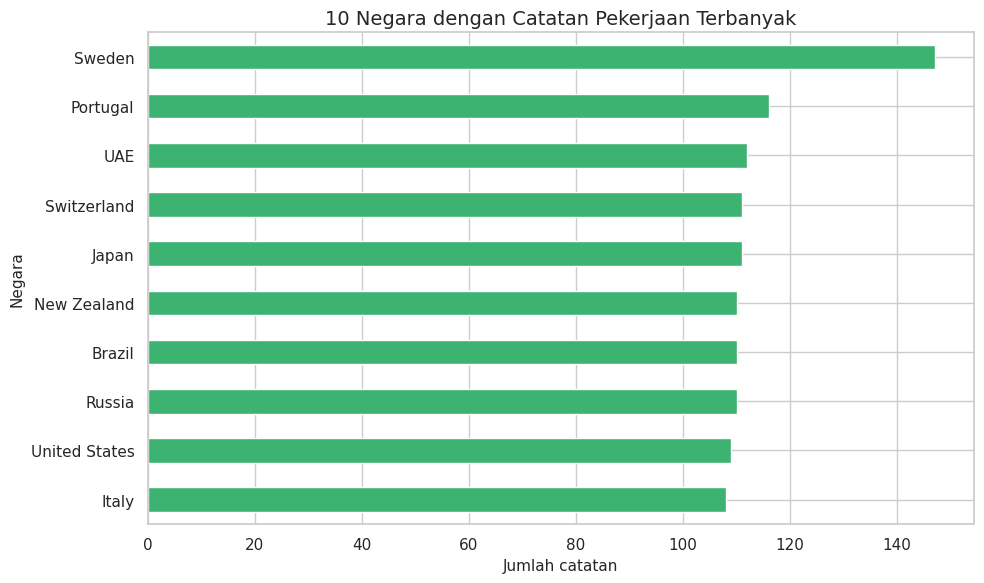

,Jumlah_Catatan
Country,
Sweden,147
Portugal,116
UAE,112
Japan,111
Switzerland,111
New Zealand,110
Russia,110
Brazil,110
United States,109


In [ ]:
if "Country" in data.columns:
    country_counts = data["Country"].value_counts().head(10).sort_values()
    ax = country_counts.plot(kind="barh", color="mediumseagreen")
    ax.set_title("10 Negara dengan Catatan Pekerjaan Terbanyak")
    ax.set_xlabel("Jumlah catatan")
    ax.set_ylabel("Negara")
    plt.tight_layout()
    plt.show()
    display(data["Country"].value_counts().head(10).rename("Jumlah_Catatan").to_frame())
else:
    print("Kolom Country tidak ditemukan.")

**Interpretasi:** negara dengan jumlah catatan tertinggi paling sering muncul pada file ini. Hindari menyebutnya sebagai negara dengan lowongan AI terbanyak di dunia tanpa validasi sumber eksternal.

## 9. Visualisasi 4 — Ketersediaan kerja dari rumah
Grafik membandingkan kategori pada kolom `Work_From_Home_Available`. Periksa kategori yang muncul pada tabel agar label grafik sesuai dengan data.

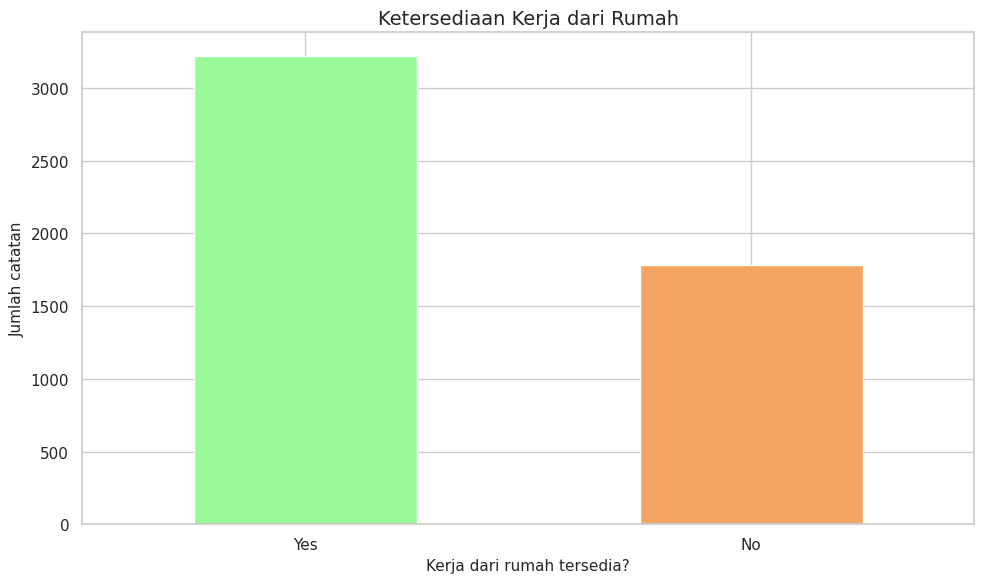

,Jumlah_Catatan
Work_From_Home_Available,
Yes,3221
No,1779


In [ ]:
if "Work_From_Home_Available" in data.columns:
    remote_counts = data["Work_From_Home_Available"].fillna("Tidak diketahui").value_counts()
    ax = remote_counts.plot(kind="bar", color=["palegreen", "sandybrown", "gray", "teal"][:len(remote_counts)])
    ax.set_title("Ketersediaan Kerja dari Rumah")
    ax.set_xlabel("Kerja dari rumah tersedia?")
    ax.set_ylabel("Jumlah catatan")
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()
    display(remote_counts.rename("Jumlah_Catatan").to_frame())
else:
    print("Kolom Work_From_Home_Available tidak ditemukan.")

**Interpretasi:** bandingkan jumlah catatan dengan opsi kerja dari rumah “Yes” dan “No” (atau kategori lain jika ada). Grafik ini menunjukkan komposisi pada dataset, bukan kebijakan semua perusahaan.


## 10. Visualisasi 5 — Tren Jumlah Catatan Pekerjaan AI Berdasarkan Tahun

Grafik garis digunakan untuk melihat perubahan jumlah catatan pekerjaan AI berdasarkan tahun posting pada kolom `Posted_Date`. Visualisasi ini membantu mengidentifikasi pola distribusi catatan pekerjaan dari tahun ke tahun.


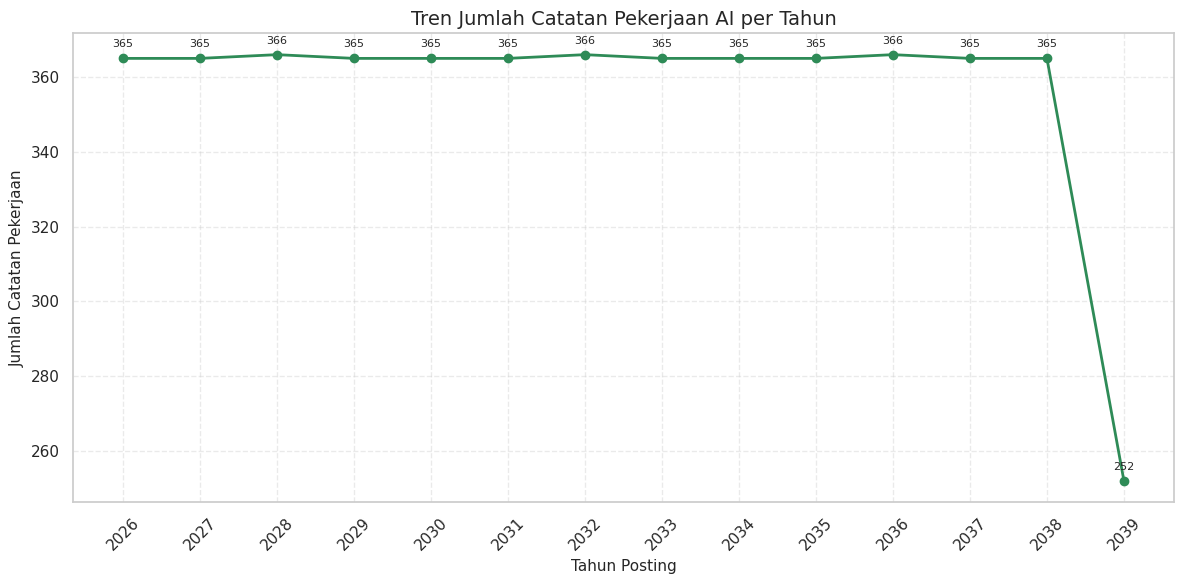

,Jumlah Catatan
Posted_Date,
2026,365
2027,365
2028,366
2029,365
2030,365
2031,365
2032,366
2033,365
2034,365


In [ ]:
# VISUALISASI 5: Tren Catatan Pekerjaan AI per Tahun

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan tanggal valid
data['Posted_Date'] = pd.to_datetime(
    data['Posted_Date'], errors='coerce'
)

date_data = data.dropna(subset=['Posted_Date']).copy()

# Hitung jumlah catatan per tahun
yearly_jobs = (
    date_data.groupby(date_data['Posted_Date'].dt.year)
    .size()
    .sort_index()
)

# Buat grafik
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_jobs.index,
    yearly_jobs.values,
    marker='o',
    markersize=6,
    linewidth=2,
    color='seagreen'
)

# Tampilkan angka di setiap titik
for year, count in yearly_jobs.items():
    plt.annotate(
        str(count),
        (year, count),
        textcoords='offset points',
        xytext=(0, 8),
        ha='center',
        fontsize=8
    )

plt.title('Tren Jumlah Catatan Pekerjaan AI per Tahun')
plt.xlabel('Tahun Posting')
plt.ylabel('Jumlah Catatan Pekerjaan')
plt.xticks(yearly_jobs.index, rotation=45)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

display(yearly_jobs.rename('Jumlah Catatan').to_frame())


**Interpretasi:** Grafik garis menunjukkan jumlah catatan pekerjaan AI berdasarkan tahun posting. Sumbu X menunjukkan tahun posting, sedangkan sumbu Y menunjukkan jumlah catatan pekerjaan pada setiap tahun.

Grafik dapat digunakan untuk melihat perubahan jumlah catatan dari tahun ke tahun. Jika garis meningkat, jumlah catatan pada tahun tersebut lebih banyak dibandingkan tahun sebelumnya. Sebaliknya, jika garis menurun, jumlah catatan lebih sedikit.

Hasil visualisasi ini menggambarkan distribusi data pada dataset yang digunakan dan tidak secara langsung membuktikan tren pasar kerja AI secara global.


## 11. Pemeriksaan tanggal dan nilai gaji ekstrem
Dataset bertema 2026 dapat memuat tanggal posting di luar tahun 2026. Periksa rentang tanggal agar keterbatasan ini bisa dijelaskan dalam laporan. Nilai gaji ekstrem juga perlu ditinjau, bukan otomatis dihapus.

In [ ]:
if "Posted_Date" in data.columns:
    print("Rentang Posted_Date:", data["Posted_Date"].min(), "sampai", data["Posted_Date"].max())
    print("\\nJumlah catatan berdasarkan tahun posting:")
    display(data["Posted_Date"].dt.year.value_counts(dropna=True).sort_index().rename("Jumlah_Catatan").to_frame())

if "Salary_USD" in data.columns:
    print("\\nRingkasan Salary_USD:")
    display(data["Salary_USD"].describe().to_frame("Salary_USD"))
    print("Persentil 99 gaji:", data["Salary_USD"].quantile(0.99))

Rentang Posted_Date: 2026-01-01 00:00:00 sampai 2039-09-09 00:00:00
\nJumlah catatan berdasarkan tahun posting:


,Jumlah_Catatan
Posted_Date,
2026,365
2027,365
2028,366
2029,365
2030,365
2031,365
2032,366
2033,365
2034,365


\nRingkasan Salary_USD:


,Salary_USD
count,5000.000000
mean,158179.958400
std,78886.439234
min,27934.000000
25%,104261.250000
50%,141886.000000
75%,191695.000000
max,718357.000000


Persentil 99 gaji: 436004.1800000006



## 12. Kesimpulan

Berdasarkan hasil analisis dan visualisasi dataset Global AI Jobs 2026, dapat ditarik beberapa kesimpulan sebagai berikut:

1. Spesialisasi AI yang paling sering tercatat dalam dataset adalah **[isi berdasarkan hasil Visualisasi 1]**.

2. Tingkat pengalaman kerja dengan median gaji tertinggi adalah **[isi berdasarkan hasil Visualisasi 2]**.

3. Negara dengan jumlah catatan pekerjaan AI terbanyak adalah **[isi berdasarkan hasil Visualisasi 3]**.

4. Ketersediaan kerja dari rumah menunjukkan bahwa **[isi berdasarkan hasil Visualisasi 4, misalnya kategori Yes atau No yang paling banyak muncul]**.

5. Berdasarkan Visualisasi 5, jumlah catatan pekerjaan AI menunjukkan pola **[isi berdasarkan grafik garis, misalnya relatif stabil atau mengalami kenaikan dan penurunan]** selama periode tahun yang tercatat dalam dataset.

Secara keseluruhan, visualisasi membantu memahami distribusi spesialisasi AI, perbandingan gaji berdasarkan pengalaman, persebaran catatan pekerjaan antarnegara, ketersediaan kerja dari rumah, serta distribusi catatan pekerjaan berdasarkan tahun posting.

**Keterbatasan:** hasil analisis bergantung pada kualitas dan kelengkapan dataset. Rentang tanggal, nilai gaji ekstrem, definisi variabel, serta sumber data perlu diperiksa sebelum hasilnya digunakan untuk menarik kesimpulan mengenai kondisi pasar kerja AI secara global.

## 13. Simpan hasil (opsional)
Kamu dapat mengunduh salinan data yang sudah dibersihkan untuk disimpan di repositori GitHub.

In [ ]:
# Jalankan jika ingin menyimpan dan mengunduh data hasil pembersihan:
# data.to_csv("global_ai_jobs_2026_cleaned.csv", index=False)
# files.download("global_ai_jobs_2026_cleaned.csv")